In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

In [ ]:
df = pd.read_csv('/marketing_campaign.csv', sep = '\t')

In [ ]:
print(df.head())

     ID  Year_Birth   Education Marital_Status   Income  Kidhome  Teenhome  \
0  5524        1957  Graduation         Single  58138.0        0         0   
1  2174        1954  Graduation         Single  46344.0        1         1   
2  4141        1965  Graduation       Together  71613.0        0         0   
3  6182        1984  Graduation       Together  26646.0        1         0   
4  5324        1981         PhD        Married  58293.0        1         0   

  Dt_Customer  Recency  MntWines  ...  NumWebVisitsMonth  AcceptedCmp3  \
0  04-09-2012       58       635  ...                  7             0   
1  08-03-2014       38        11  ...                  5             0   
2  21-08-2013       26       426  ...                  4             0   
3  10-02-2014       26        11  ...                  6             0   
4  19-01-2014       94       173  ...                  5             0   

   AcceptedCmp4  AcceptedCmp5  AcceptedCmp1  AcceptedCmp2  Complain  \
0             0

In [ ]:
df.tail()

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
2235,10870,1967,Graduation,Married,61223.0,0,1,13-06-2013,46,709,...,5,0,0,0,0,0,0,3,11,0
2236,4001,1946,PhD,Together,64014.0,2,1,10-06-2014,56,406,...,7,0,0,0,1,0,0,3,11,0
2237,7270,1981,Graduation,Divorced,56981.0,0,0,25-01-2014,91,908,...,6,0,1,0,0,0,0,3,11,0
2238,8235,1956,Master,Together,69245.0,0,1,24-01-2014,8,428,...,3,0,0,0,0,0,0,3,11,0
2239,9405,1954,PhD,Married,52869.0,1,1,15-10-2012,40,84,...,7,0,0,0,0,0,0,3,11,1


In [ ]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

In [ ]:

print(df.shape)
df.describe()

(2240, 29)


,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.0,2240.0,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,3.0,11.0,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.0,0.0,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.0,11.0,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.0,11.0,1.000000


In [ ]:
data = df.copy()
data.drop(columns = ["ID","Z_CostContact","Z_Revenue","Year_Birth"],errors = "ignore",inplace = True)
if "Year_Birth" in df.columns:
  data["Age"] = 2026-df["Year_Birth"]
if "Dt_Customer" in data.columns:
 dates = pd.to_datetime(data["Dt_Customer"], dayfirst=True, errors="coerce")
 data["Customer_Tenure_Days"] = (dates.max() - dates).dt.days
 data.drop(columns=["Dt_Customer"], inplace=True)
if "Age" in data.columns:
    data.loc[~data["Age"].between(18, 100), "Age"] = np.nan
for col in data.columns:
  if data[col].dtype == "object":
        data[col] = data[col].fillna(data[col].mode()[0])
  else:
        data[col] = data[col].fillna(data[col].median())
X = pd.get_dummies(data, drop_first=True, dtype=int)
X_scaled = StandardScaler().fit_transform(X)




In [ ]:
print(X.dtypes)

Income                     float64
Kidhome                      int64
Teenhome                     int64
Recency                      int64
MntWines                     int64
MntFruits                    int64
MntMeatProducts              int64
MntFishProducts              int64
MntSweetProducts             int64
MntGoldProds                 int64
NumDealsPurchases            int64
NumWebPurchases              int64
NumCatalogPurchases          int64
NumStorePurchases            int64
NumWebVisitsMonth            int64
AcceptedCmp3                 int64
AcceptedCmp4                 int64
AcceptedCmp5                 int64
AcceptedCmp1                 int64
AcceptedCmp2                 int64
Complain                     int64
Response                     int64
Age                        float64
Customer_Tenure_Days         int64
Education_Basic              int64
Education_Graduation         int64
Education_Master             int64
Education_PhD                int64
Marital_Status_Alone

In [ ]:
print(data.shape)

(2240, 26)


In [ ]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 35 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Income                   2240 non-null   float64
 1   Kidhome                  2240 non-null   int64  
 2   Teenhome                 2240 non-null   int64  
 3   Recency                  2240 non-null   int64  
 4   MntWines                 2240 non-null   int64  
 5   MntFruits                2240 non-null   int64  
 6   MntMeatProducts          2240 non-null   int64  
 7   MntFishProducts          2240 non-null   int64  
 8   MntSweetProducts         2240 non-null   int64  
 9   MntGoldProds             2240 non-null   int64  
 10  NumDealsPurchases        2240 non-null   int64  
 11  NumWebPurchases          2240 non-null   int64  
 12  NumCatalogPurchases      2240 non-null   int64  
 13  NumStorePurchases        2240 non-null   int64  
 14  NumWebVisitsMonth       

In [ ]:
print(data.isnull().sum())

Education               0
Marital_Status          0
Income                  0
Kidhome                 0
Teenhome                0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Response                0
Age                     0
Customer_Tenure_Days    0
dtype: int64


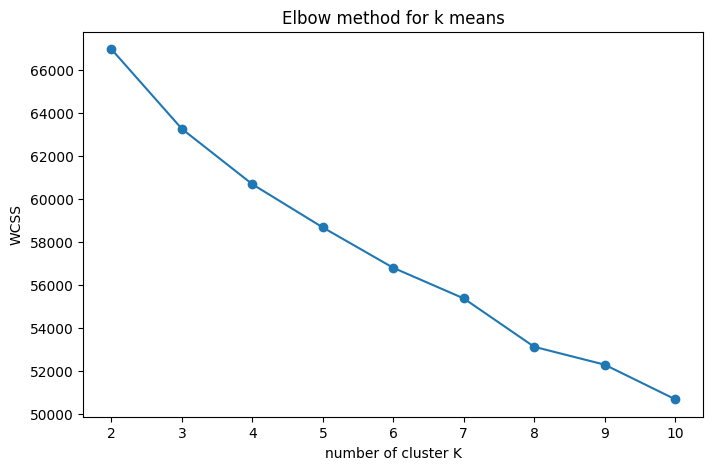

In [ ]:
from sklearn.cluster import KMeans,DBSCAN
WCSS = []
k_values = range(2,11)
for k in k_values:
  model = KMeans(n_clusters = k,random_state = 42 , n_init = 10)
  model.fit(X_scaled)
  WCSS.append(model.inertia_)
plt.figure(figsize = (8,5))
plt.plot(list(k_values),WCSS,marker = 'o')
plt.xlabel("number of cluster K")
plt.ylabel("WCSS")
plt.title("Elbow method for k means")
plt.xticks(list(k_values))
plt.grid=(True)
plt.show()


K = 2, Silhouette Score = 0.1775
K = 3, Silhouette Score = 0.1165
K = 4, Silhouette Score = 0.1166
K = 5, Silhouette Score = 0.1213
K = 6, Silhouette Score = 0.0834
K = 7, Silhouette Score = 0.0814
K = 8, Silhouette Score = 0.0887
K = 9, Silhouette Score = 0.0813
K = 10, Silhouette Score = 0.0892


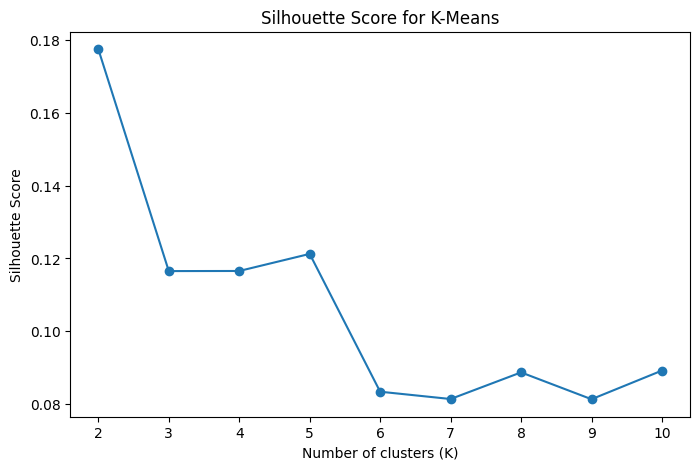

In [ ]:
from sklearn.metrics import silhouette_score
silhouette_scores = []
for k in range(2,11):
  model = KMeans(n_clusters = k,random_state = 42,n_init=10)
  labels = model.fit_predict(X_scaled)
  score = silhouette_score(X_scaled,labels)
  silhouette_scores.append(score)
  print(f"K = {k}, Silhouette Score = {score:.4f}")
plt.figure(figsize = (8,5))
plt.plot(range(2,11),silhouette_scores,marker = "o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for K-Means")
plt.xticks(list(k_values))
plt.grid=(True)
plt.show()



In [ ]:
best_k = list(range(2,11))[
    np.argmax(silhouette_scores)
]
print("best K: ", best_k)

best K:  2


In [ ]:
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)
print("K-Means cluster sizes:")
print(pd.Series(kmeans_labels).value_counts().sort_index())

K-Means cluster sizes:
0    1353
1     887
Name: count, dtype: int64


In [ ]:
dbscan = DBSCAN(eps = 5,min_samples = 10)
dbscan_labels = dbscan.fit_predict(X_scaled)
unique_labels = set(dbscan_labels)
n_cluster = len(unique_labels - {-1})
n_noise = np.sum(dbscan_labels == -1)
print("DBSCAN clusters : ",n_cluster)
print("Noise points: ",n_noise)
print("Noise percentage:", round(n_noise / len(dbscan_labels) * 100, 2), "%")
print("\nCluster sizes:")
print(pd.Series(dbscan_labels).value_counts().sort_index())

DBSCAN clusters :  4
Noise points:  265
Noise percentage: 11.83 %

Cluster sizes:
-1     265
 0    1864
 1      52
 2      52
 3       7
Name: count, dtype: int64


In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Explained variance ratio: [0.18738375 0.06375804]
Total variance retained: 25.11 %


In [ ]:
pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "KMeans_Cluster": kmeans_labels,
    "DBSCAN_Cluster": dbscan_labels
})


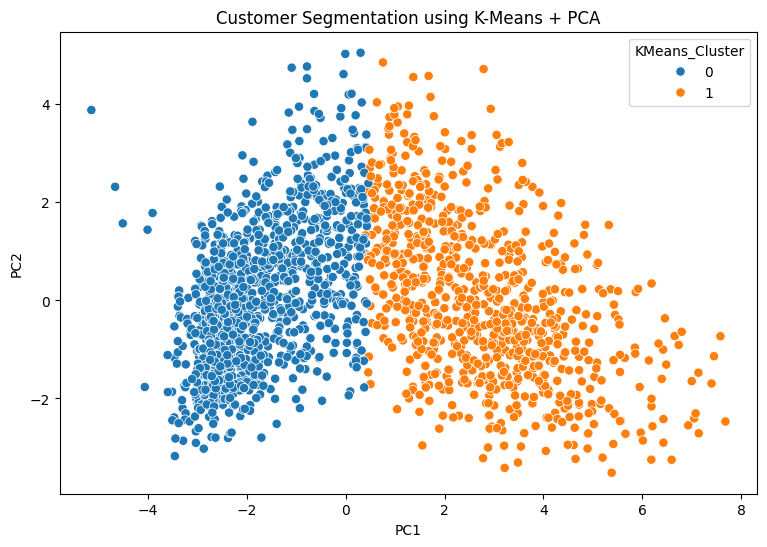

In [ ]:
import seaborn as sns
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2",
    hue="KMeans_Cluster", palette="tab10", s=45
)
plt.title("Customer Segmentation using K-Means + PCA")
plt.show()


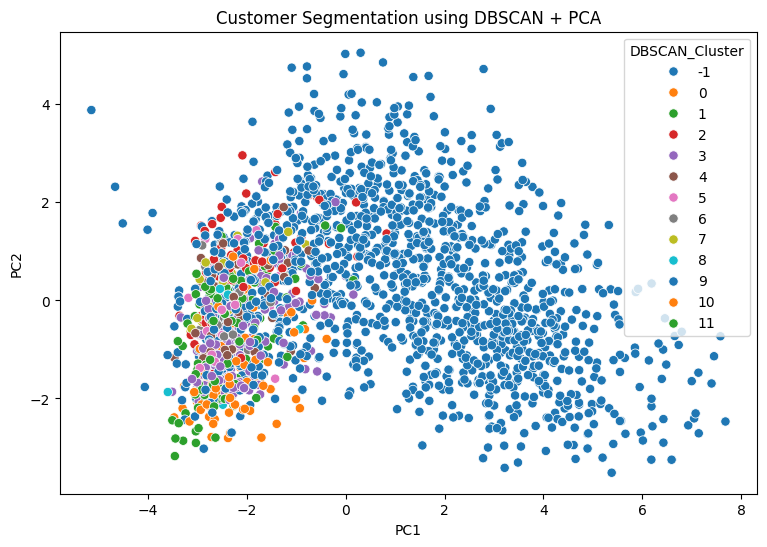

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df, x="PC1", y="PC2",
    hue="DBSCAN_Cluster", palette="tab10", s=45
)
plt.title("Customer Segmentation using DBSCAN + PCA")
plt.show()

In [ ]:
from sklearn.manifold import TSNE
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate="auto",
    init="pca",
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

tsne_df = pd.DataFrame({
    "tSNE1": X_tsne[:, 0],
    "tSNE2": X_tsne[:, 1],
    "KMeans_Cluster": kmeans_labels,
    "DBSCAN_Cluster": dbscan_labels
})



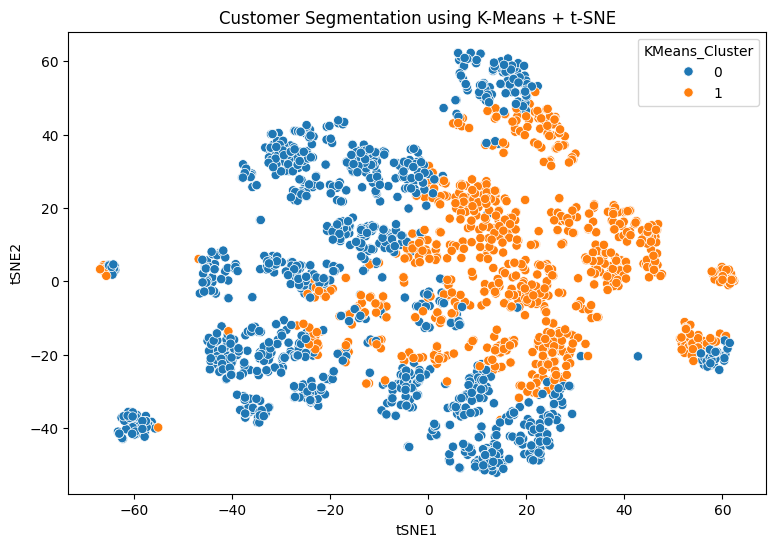

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tsne_df, x="tSNE1", y="tSNE2",
    hue="KMeans_Cluster", palette="tab10", s=45
)
plt.title("Customer Segmentation using K-Means + t-SNE")
plt.show()

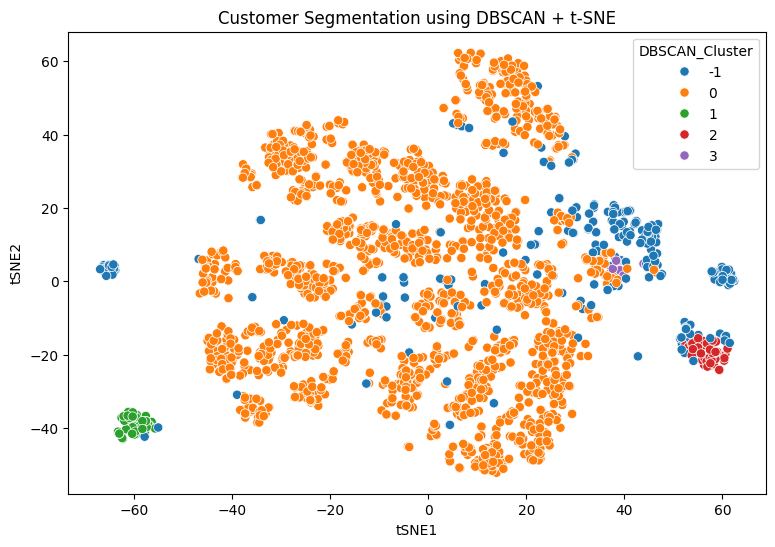

In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=tsne_df, x="tSNE1", y="tSNE2",
    hue="DBSCAN_Cluster", palette="tab10", s=45
)
plt.title("Customer Segmentation using DBSCAN + t-SNE")
plt.show()


In [ ]:

def safe_silhouette(X_data, labels):
    # Exclude DBSCAN noise, if present
    mask = labels != -1
    labels_used = labels[mask]
    X_used = X_data[mask]

    if len(np.unique(labels_used)) < 2:
        return np.nan

    if len(labels_used) <= len(np.unique(labels_used)):
        return np.nan

    return silhouette_score(X_used, labels_used)

comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "DBSCAN"],
    "Number_of_Clusters": [
        len(set(kmeans_labels)),
        len(set(dbscan_labels) - {-1})
    ],
    "Noise_Points": [
        0,
        int(np.sum(dbscan_labels == -1))
    ],
    "Silhouette_Score": [
        safe_silhouette(X_scaled, kmeans_labels),
        safe_silhouette(X_scaled, dbscan_labels)
    ]
})

display(comparison)


,Algorithm,Number_of_Clusters,Noise_Points,Silhouette_Score
0,K-Means,2,0,0.177489
1,DBSCAN,4,265,0.176353


In [ ]:

results = df.copy()
results["KMeans_Cluster"] = kmeans_labels
results["DBSCAN_Cluster"] = dbscan_labels
results["PCA_1"] = X_pca[:, 0]
results["PCA_2"] = X_pca[:, 1]
results["tSNE_1"] = X_tsne[:, 0]
results["tSNE_2"] = X_tsne[:, 1]

results.to_csv("customer_segmentation_results.csv", index=False)

print("Saved customer_segmentation_results.csv")
display(results.head())



Saved customer_segmentation_results.csv


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,Complain,Z_CostContact,Z_Revenue,Response,KMeans_Cluster,DBSCAN_Cluster,PCA_1,PCA_2,tSNE_1,tSNE_2
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,0,3,11,1,1,0,3.857847,-0.565804,24.703880,2.581702
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,0,3,11,0,0,0,-2.373203,-0.643220,-32.509590,-20.771282
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,0,3,11,0,1,0,1.643098,-0.422534,26.911644,-19.033684
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,0,3,11,0,0,0,-2.514099,-1.651863,10.270621,-50.075260
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,0,3,11,0,0,0,-0.506977,0.141613,-16.152536,13.088717
